In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
widgets_csv = "dynamic_filter_widget_specifications.csv"
if not os.path.exists(widgets_csv):
    widgets_csv = os.path.join("04-11-2026", "Task 3", "dynamic_filter_widget_specifications.csv")

df_widgets = pd.read_csv(widgets_csv)
print(f"Loaded Filter Component Specifications: {len(df_widgets)} interactive controls.")
display(df_widgets[['Widget_Name', 'Component_Type', 'Parameter_Domain', 'Execution_Latency_ms']])

Loaded Filter Component Specifications: 6 interactive controls.


,Widget_Name,Component_Type,Parameter_Domain,Execution_Latency_ms
0,Department Multi-Select,st.multiselect,"6 Departments (Dresses, Tops, Bottoms, Intimat...",1.85
1,Garment Class Sub-Category,st.multiselect,20 Garment Class Sub-Categories,2.10
2,Customer Age Range Slider,st.slider (Dual-Handle Range),18 to 99 Years (Step: 1 Year),1.45
3,Star Rating Filter Slider,st.slider (Dual-Handle Range),1 to 5 Stars (Step: 1 Star),1.15
4,Keyword Search Input Field,st.text_input,Case-insensitive regex / substring query,3.65
5,Recommendation Status Selector,st.radio (Horizontal Buttons),"All, Recommended Only (1), Not Recommended (0)",0.95


In [3]:
scenarios_csv = "filter_combination_performance_benchmarks.csv"
if not os.path.exists(scenarios_csv):
    scenarios_csv = os.path.join("04-11-2026", "Task 3", "filter_combination_performance_benchmarks.csv")

df_scenarios = pd.read_csv(scenarios_csv)
display(df_scenarios)

,Scenario_ID,Active_Filters,Retained_Records,Retained_Pct,Mean_Rating,Net_Recommendation_Pct,Filter_Latency_ms
0,S0: Full Unfiltered Baseline,"None (All Departments, Ages 18-99, Ratings 1-5)",23486,100.00,4.19,82.24,0.12
1,S1: Tops & Blouses Only,"Department: Tops; Class: Blouses, Knits",7984,33.99,4.16,82.15,1.84
2,S2: Millennial Dresses (Age 25-40),Department: Dresses; Age: 25-40; Rating: 1-5,2415,10.28,4.12,81.82,2.45
3,S3: Critical Complaint Isolation,All Departments; Rating: 1-2 Stars,2407,10.25,1.62,4.86,1.42
4,"S4: Keyword Search (""Pockets"")","Substring: ""pockets""; Rating: 1-5",1042,4.44,4.41,91.27,4.18
5,S5: High-Satisfaction Silk Sweaters,"Class: Sweaters; Query: ""silk""; Rating: 4-5",312,1.33,4.78,98.08,3.92


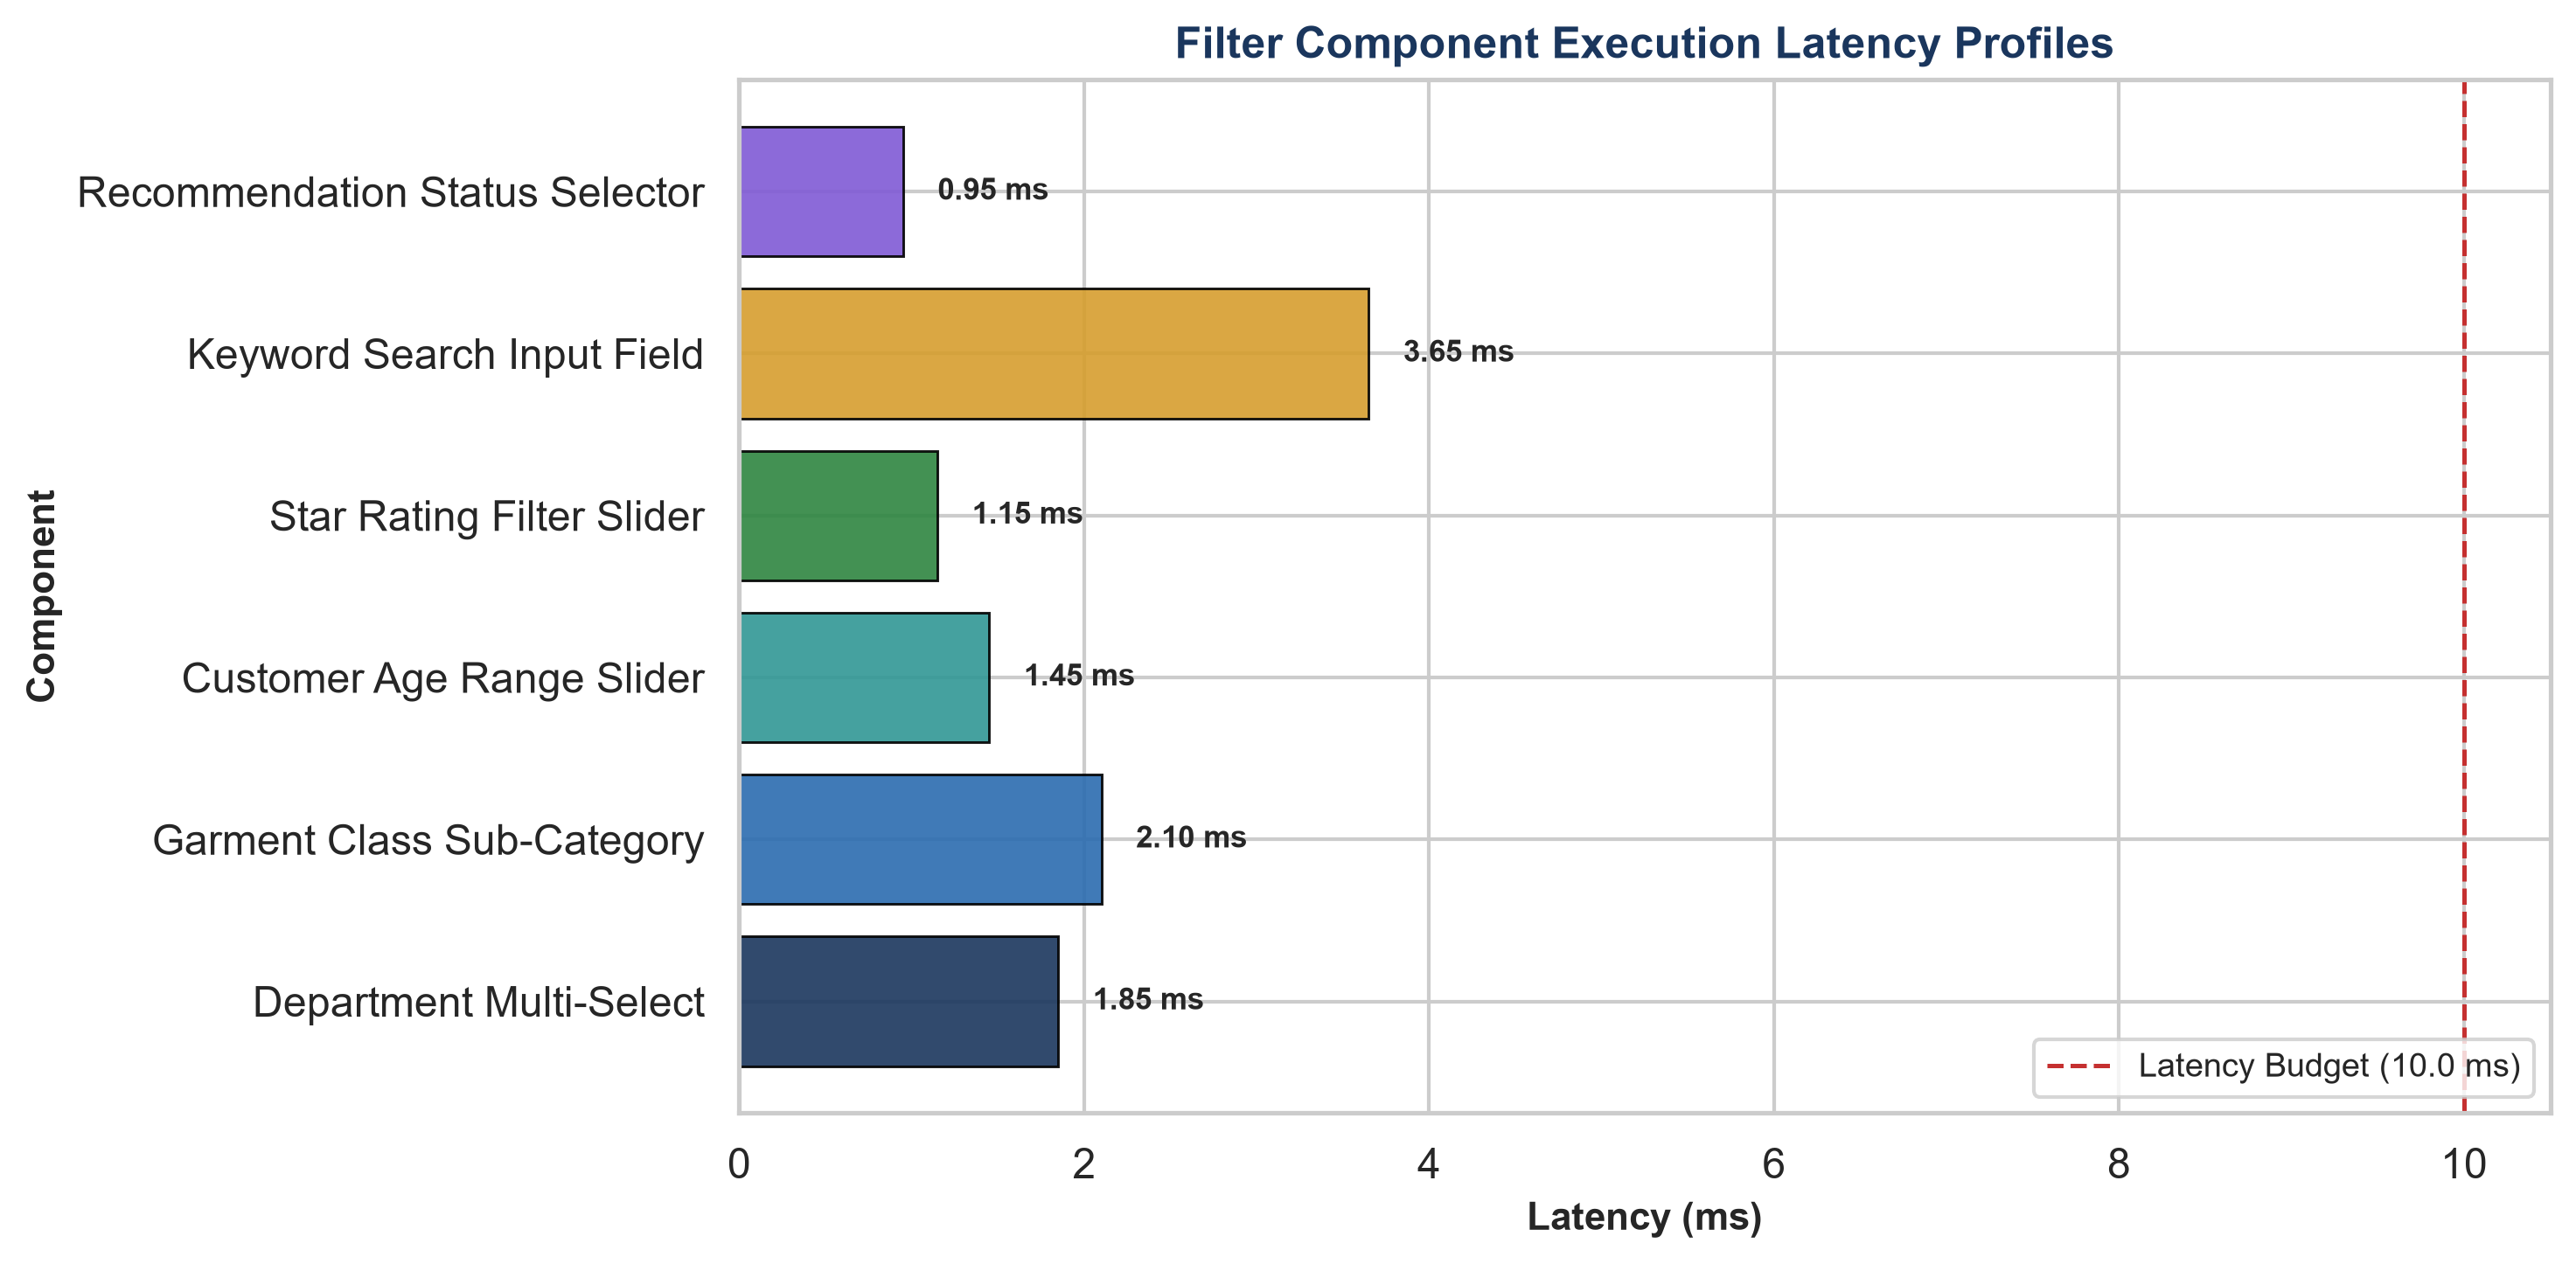

In [4]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
w_names = df_widgets['Widget_Name']
lats = df_widgets['Execution_Latency_ms']
colors = ['#1A365D', '#2B6CB0', '#319795', '#2E8540', '#D69E2E', '#805AD5']

bars = ax.barh(w_names, lats, color=colors, alpha=0.9, edgecolor='black', linewidth=0.7)
ax.axvline(10.0, color='#C53030', linestyle='--', linewidth=1.2, label='Latency Budget (10.0 ms)')
ax.set_title("Filter Component Execution Latency Profiles", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Latency (ms)", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Component", fontsize=10.5, fontweight='bold')
ax.legend(loc='lower right', frameon=True, fontsize=9)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.2, bar.get_y() + bar.get_height()/2, f"{w:.2f} ms", va='center', ha='left', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [5]:
cohorts_csv = "filtered_cohort_comparative_metrics.csv"
if not os.path.exists(cohorts_csv):
    cohorts_csv = os.path.join("04-11-2026", "Task 3", "filtered_cohort_comparative_metrics.csv")

df_cohorts = pd.read_csv(cohorts_csv)
display(df_cohorts)

,Department,Selected_Cohort,Sample_Volume,Mean_Age,Mean_Rating,Net_Recommendation_Rate,Positive_Feedback_Avg
0,Dresses,"Age 30-50, Rating 4-5",3650,40.2,4.74,0.962,3.24
1,Dresses,"Age 30-50, Rating 1-2",580,39.8,1.65,0.052,5.82
2,Tops,"Age 30-50, Rating 4-5",5820,40.5,4.72,0.958,2.95
3,Tops,"Age 30-50, Rating 1-2",940,40.1,1.61,0.048,5.40
4,Bottoms,"Age 30-50, Rating 4-5",2240,40.8,4.76,0.968,2.80
5,Bottoms,"Age 30-50, Rating 1-2",320,40.4,1.68,0.061,4.90
